# Welcome to Colab!

In [6]:
import numpy as np
data = np.genfromtxt("sky130_nmos_idvg_vds0p1.csv", delimiter=",", names=True)
print(data.dtype.names, len(data))

('VGS_V', 'VDS_V', 'VBS_V', 'ID_A', 'IG_A', 'IB_A') 37


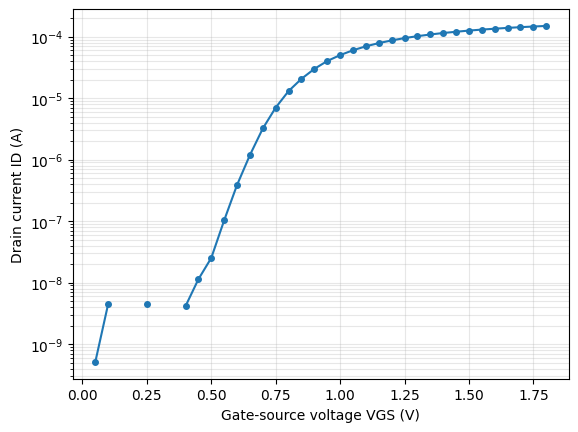

In [7]:
import matplotlib.pyplot as plt
vg = data["VGS_V"]
id_a = data["ID_A"]
id_for_plot = np.where(id_a > 0, id_a, np.nan)
plt.semilogy(vg, id_for_plot, "o-", markersize=4)
plt.xlabel("Gate-source voltage VGS (V)")
plt.ylabel("Drain current ID (A)")
plt.grid(True, which="both", alpha=0.3)
plt.show()

In [8]:
from scipy.stats import linregress
fit_mask = (vg >= 0.45) & (vg <= 0.65) & (id_a > 0)
fit = linregress(vg[fit_mask], np.log10(id_a[fit_mask]))
ss = 1000 / fit.slope
print(f"点数 = {fit_mask.sum()}, 斜率 = {fit.slope:.3f} dec/V, R² = {fit.rvalue**2:.4f}, SS = {ss:.2f} mV/dec")

点数 = 5, 斜率 = 10.455 dec/V, R² = 0.9936, SS = 95.65 mV/dec


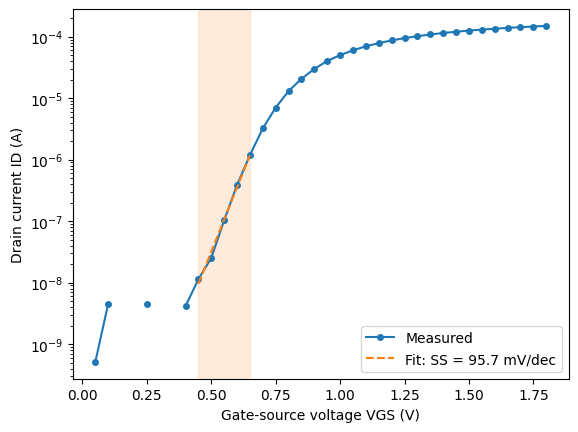

In [9]:
vg_fit = np.linspace(0.45, 0.65, 100)
id_fit = 10 ** (fit.intercept + fit.slope * vg_fit)
plt.semilogy(vg, id_for_plot, "o-", markersize=4, label="Measured")
plt.axvspan(0.45, 0.65, color="tab:orange", alpha=0.15)
plt.semilogy(vg_fit, id_fit, "--", color="tab:orange", label=f"Fit: SS = {ss:.1f} mV/dec")
plt.xlabel("Gate-source voltage VGS (V)")
plt.ylabel("Drain current ID (A)")
plt.legend()
plt.savefig("sky130_nmos_ss.png", dpi=200, bbox_inches="tight")
plt.show()